# Task 1 — Model Final, Ketahanan, dan Prediksi Data Uji

**Ruang lingkup.** Bagian ini menyelesaikan Task 1 dengan:
- butir (g): evaluasi model final dengan tiga seed, kurva belajar, dan ansambel tiga seed;
- butir (f): ketahanan model final ketika sensor tidak terekam;
- butir (e): diagnosis lanjutan, yaitu apakah normalisasi per lini dan augmentasi membantu pada skenario pergeseran domain yang ekstrem (pelatihan hanya lini A, pengujian lini B);
- butir (d): perbandingan *co-teaching* dengan label smoothing pada noise buatan;
- keluaran: `prediksi_klasifikasi.csv` untuk 16.000 unit uji dan bobot model.

**Model final.** Fusi tingkat fitur dengan *modality dropout* 0,3 dan augmentasi kecerahan/kontras pada citra (R2 pada notebook domain shift, macro-F1 validasi 0,838 pada seed 0). Pada seed 0, selisih R2 terhadap model dasar tanpa augmentasi (0,836) hanya 0,003 dan belum dapat dianggap bermakna. Augmentasi dipertahankan karena murah, tidak menurunkan hasil, dan sesuai dengan perbedaan kecerahan dan kontras antar lini yang terukur; apakah pilihan ini benar-benar lebih baik dinilai ulang dengan tiga seed pada bagian 6.

**Alur.** 0 Persiapan → 1 Model final, tiga seed → 2 Kurva belajar → 3 Sensor tidak terekam → 4 Prediksi uji → 5 Diagnosis domain → 6 Perbandingan dengan model dasar → 7 Co-teaching → 8 Ringkasan dan kesimpulan → 9 Penyimpanan hasil.

## 0. Persiapan lingkungan dan data

Eksperimen dijalankan di Google Colab dengan GPU NVIDIA T4. Kode pada `data.py`, `models.py`, `train_utils.py`, `fusion.py`, dan `robust.py` dipakai ulang dari repositori. Berkas baru `coteaching.py` memuat pelatihan co-teaching.

In [1]:
import torch, numpy, pandas, sklearn, sys
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", numpy.__version__,
      "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)
print("GPU tersedia:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Aktifkan T4 GPU dulu: Runtime -> Change runtime type"

Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
GPU tersedia: True


In [2]:
import os
if not os.path.exists('/content/data/klasifikasi_train.npz'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
!ls /content/data

Downloading...
From (original): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb
From (redirected): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb&confirm=t&uuid=02d17072-af1e-4cd3-8dc5-90be62088d29
To: /content/data_uts_dl.zip
100% 396M/396M [00:03<00:00, 121MB/s]
clustering_meta.csv  klasifikasi_test_meta.csv	 klasifikasi_train.npz
clustering.npz	     klasifikasi_test.npz	 rul_test.csv.gz
kamus_data.md	     klasifikasi_train_meta.csv  rul_train.csv.gz


In [3]:
from google.colab import userdata
import os
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/rafiptrnto/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "rafiptrnto"
!git config user.email "rafiputranto665@gmail.com"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git pull --no-edit upstream main
!git checkout -B task1-final
!mkdir -p kode/task1_klasifikasi/hasil kode/task1_klasifikasi/bobot
!ls kode/task1_klasifikasi

Cloning into '/content/UTSDEEPLEARNING'...
remote: Enumerating objects: 95, done.
remote: Counting objects: 100% (95/95), done.
remote: Compressing objects: 100% (76/76), done.
remote: Total 95 (delta 26), reused 47 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (95/95), 1014.40 KiB | 3.29 MiB/s, done.
Resolving deltas: 100% (26/26), done.
/content/UTSDEEPLEARNING
remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (1/1), 900 bytes | 900.00 KiB/s, done.
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> upstream/main
Updating 5eeec2b..62c1ee3
Fast-forward
 kode/task1_klasifikasi/task1_domain_noise.ipynb | 2418 +++++++++++++++++++++++
 1 file changed, 2418 insertions(+)
 create mode 100644 kode/task1_klasifikasi/task1_domain_noise.ipynb
Switched to a new branch 'task1-f

 `coteaching.py`

*Co-teaching* melatih dua jaringan sekaligus. Pada setiap batch, tiap jaringan memilih sampel dengan loss terkecil (yang kemungkinan besar berlabel benar) dan memberikannya kepada jaringan lain untuk dipelajari. Proporsi sampel yang dibuang (*forget rate*) naik bertahap dari 0 sampai nilai akhir dalam lima epoch pertama, karena pada awal pelatihan loss belum informatif. Pemilihan sampel memakai loss tanpa bobot kelas agar tidak bias terhadap kelas mayoritas, sedangkan gradien tetap memakai bobot kelas seperti model lainnya.

In [4]:
%%writefile /content/UTSDEEPLEARNING/kode/task1_klasifikasi/coteaching.py
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import f1_score
from fusion import drop_sensor
from robust import get_loader3, predict3, prep_img

def fit_coteaching(m1, m2, Xi, Xs, y, lc, tr_idx, va_idx, epochs=15, lr=1e-3, bs=256,
                   class_weight=None, p_drop=0.3, aug=False, forget=0.10, warm=5,
                   device='cuda', seed=0, y_eval=None):
    torch.manual_seed(seed); np.random.seed(seed)
    y_eval = y if y_eval is None else y_eval
    m1.to(device); m2.to(device)
    wv = torch.ones(7, device=device) if class_weight is None else torch.tensor(class_weight, dtype=torch.float32, device=device)
    o1 = torch.optim.AdamW(m1.parameters(), lr=lr, weight_decay=1e-4)
    o2 = torch.optim.AdamW(m2.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(tr_idx) / bs))
    s1 = torch.optim.lr_scheduler.OneCycleLR(o1, max_lr=lr, total_steps=steps)
    s2 = torch.optim.lr_scheduler.OneCycleLR(o2, max_lr=lr, total_steps=steps)
    tl = get_loader3(Xi, Xs, y, lc, tr_idx, bs, True)
    vl = get_loader3(Xi, Xs, y_eval, lc, va_idx)
    hist = []
    for ep in range(epochs):
        rate = forget * min(1.0, ep / warm)
        m1.train(); m2.train(); tot = 0.0
        for xi, xs, yb, lb in tl:
            xi, xs, yb, lb = xi.to(device), xs.to(device), yb.to(device), lb.to(device)
            xi = prep_img(xi, lb, None, aug, True)
            xs = drop_sensor(xs, p_drop)
            u1 = F.cross_entropy(m1(xi, xs), yb, reduction='none')
            u2 = F.cross_entropy(m2(xi, xs), yb, reduction='none')
            k = max(1, int(round((1 - rate) * len(yb))))
            pilih1 = torch.argsort(u1.detach())[:k]      # sampel terpilih oleh jaringan 1
            pilih2 = torch.argsort(u2.detach())[:k]      # sampel terpilih oleh jaringan 2
            w = wv[yb]
            loss1 = (u1 * w)[pilih2].mean()              # jaringan 1 belajar dari pilihan jaringan 2
            loss2 = (u2 * w)[pilih1].mean()              # jaringan 2 belajar dari pilihan jaringan 1
            o1.zero_grad(); loss1.backward(); o1.step(); s1.step()
            o2.zero_grad(); loss2.backward(); o2.step(); s2.step()
            tot += loss1.item() * len(yb)
        P = predict3(m1, vl, device)
        f1 = f1_score(y_eval[va_idx], P.argmax(1), average='macro')
        hist.append((tot / len(tr_idx), f1))
        print(f"ep {ep+1}: forget {rate:.3f} | loss {hist[-1][0]:.4f} | val macro-F1 (jaringan 1) {f1:.4f}")
    return hist

Writing /content/UTSDEEPLEARNING/kode/task1_klasifikasi/coteaching.py


### Pemuatan data dan konfigurasi

Konfigurasi identik dengan notebook sebelumnya: pembagian 80/20 terstratifikasi (seed 0), statistik sensor hanya dari data latih, kanal *mask* untuk sensor tidak terekam, dan bobot kelas akar dari 1/frekuensi. Seed 0 pada pembagian data dipertahankan untuk ketiga seed model, sehingga variasi yang diukur berasal dari inisialisasi dan urutan data, bukan dari perbedaan data validasi.

Pengaturan opsional: `BANDINGKAN_R0` (bagian 6) dan `RUN_COTEACHING` (bagian 7). Keduanya diletakkan setelah prediksi uji, sehingga berkas prediksi sudah tersimpan sebelum eksperimen tambahan dimulai.

In [5]:
import sys, json, os
sys.path.append('/content/UTSDEEPLEARNING/kode/task1_klasifikasi')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.metrics import f1_score
from IPython.display import Markdown, display
from data import *
from models import *
from train_utils import *
from fusion import *
from robust import *
from coteaching import *

SPLIT_SEED = 0
SEEDS = [0, 1, 2]
EPOCHS = 15
device = 'cuda'
BANDINGKAN_R0 = True
RUN_COTEACHING = True
IMG_ONLY_F1 = 0.6131      # macro-F1 model gambar saja (notebook fusi, seed 0), pembanding untuk sensor tidak terekam

REPO = '/content/UTSDEEPLEARNING'
OUT = f'{REPO}/kode/task1_klasifikasi/hasil'
BOBOT = f'{REPO}/kode/task1_klasifikasi/bobot'

img, sen, meta, y = load('train')
tr_idx, va_idx = make_split(meta, y, seed=SPLIT_SEED)
m, s = sensor_stats(sen[tr_idx])
X_sen = prep_sensor(sen, m, s)
X_img = img[:, None]
lc = lini_code(meta)
yv = y[va_idx]
lini_va = meta['lini'].values[va_idx]
cw = (len(y) / (7 * np.bincount(y))) ** 0.5
mu_l, sd_l = lini_stats(img, lc, tr_idx)
vl_all = get_loader3(X_img, X_sen, y, lc, va_idx)

# data uji, diproses dengan statistik data latih
img_te, sen_te, meta_te, _ = load('test')
X_img_te = img_te[:, None]
X_sen_te = prep_sensor(sen_te, m, s)
lc_te = lini_code(meta_te)
te_idx = np.arange(len(meta_te))
te_loader = get_loader3(X_img_te, X_sen_te, np.zeros(len(meta_te), dtype=np.int64), lc_te, te_idx)

print("latih/valid:", len(tr_idx), len(va_idx), "| uji:", len(meta_te))
print("proporsi lini uji:", meta_te['lini'].value_counts(normalize=True).round(3).to_dict())
print("kolom metadata uji:", list(meta_te.columns))

HASIL, PRED, INFO = {}, {}, {}
def simpan():
    with open(f'{OUT}/final_tiga_seed.json', 'w') as f:
        json.dump({'seeds': SEEDS, 'epochs': EPOCHS, 'info': INFO, 'hasil': HASIL}, f, indent=2)

def ringkas(nama, y_true, y_pred, lini):
    per = f1_score(y_true, y_pred, average=None, labels=list(range(7)))
    HASIL[nama] = dict(
        total=float(f1_score(y_true, y_pred, average='macro')),
        A=float(f1_score(y_true[lini == 'A'], y_pred[lini == 'A'], average='macro')),
        B=float(f1_score(y_true[lini == 'B'], y_pred[lini == 'B'], average='macro')),
        per_kelas={k: float(v) for k, v in zip(KELAS, per)})
    h = HASIL[nama]
    print(f"{nama}: macro-F1 {h['total']:.4f} | lini A {h['A']:.4f} | lini B {h['B']:.4f}")
    simpan()

latih/valid: 38400 9600 | uji: 16000
proporsi lini uji: {'B': 0.6, 'A': 0.4}
kolom metadata uji: ['indeks', 'id_unit', 'lini', 'shift', 'id_mesin', 'batch_material']


## 1. Model final: tiga seed

Model final dilatih dengan tiga seed (0, 1, 2) pada pembagian data yang sama. Untuk setiap seed dicatat riwayat pelatihan (loss latih dan macro-F1 validasi per epoch), probabilitas pada data validasi (dengan sensor ada dan sensor dikosongkan), probabilitas pada data uji, dan bobot model. Hasil akhir dilaporkan sebagai rerata dan simpangan baku antar seed, serta hasil ansambel (rerata probabilitas tiga model).

In [6]:
FINAL = {}
def latih_final(seed, aug=True, norm=False, simpan_bobot=True, nama_bobot='fusi_a1_aug'):
    nrm = (mu_l, sd_l) if norm else None
    model = FusionNet()
    hist = fit3(model, X_img, X_sen, y, lc, tr_idx, va_idx, epochs=EPOCHS, class_weight=cw, p_drop=0.3,
                aug=aug, norm=nrm, device=device, seed=seed)
    r = dict(hist=hist,
             val=predict3(model, vl_all, device, norm=nrm),
             val_off=predict3(model, vl_all, device, norm=nrm, sensor_off=True),
             test=predict3(model, te_loader, device, norm=nrm))
    if simpan_bobot:
        torch.save(model.state_dict(), f'{BOBOT}/{nama_bobot}_seed{seed}.pt')
    del model; torch.cuda.empty_cache()
    return r

for sd in SEEDS:
    print(f"--- seed {sd} ---")
    FINAL[sd] = latih_final(sd)
    ringkas(f'Final seed {sd}', yv, FINAL[sd]['val'].argmax(1), lini_va)

P_ens = np.mean([FINAL[sd]['val'] for sd in SEEDS], axis=0)
ringkas('Final ansambel 3 seed', yv, P_ens.argmax(1), lini_va)

tab = pd.DataFrame({sd: {k: HASIL[f'Final seed {sd}'][k] for k in ['total', 'A', 'B']} for sd in SEEDS}).T
tab.columns = ['macro-F1', 'lini A', 'lini B']
tab.loc['rerata'] = tab.loc[SEEDS].mean()
tab.loc['simpangan baku'] = tab.loc[SEEDS].std(ddof=1)
tab.loc['ansambel'] = [HASIL['Final ansambel 3 seed'][k] for k in ['total', 'A', 'B']]
display(tab.round(4))

--- seed 0 ---
ep 1: loss 1.8190 | val macro-F1 0.3122
ep 2: loss 1.4616 | val macro-F1 0.4945
ep 3: loss 1.1049 | val macro-F1 0.7002
ep 4: loss 0.9426 | val macro-F1 0.6208
ep 5: loss 0.8481 | val macro-F1 0.7325
ep 6: loss 0.7606 | val macro-F1 0.7372
ep 7: loss 0.7113 | val macro-F1 0.7093
ep 8: loss 0.6508 | val macro-F1 0.8034
ep 9: loss 0.6017 | val macro-F1 0.8164
ep 10: loss 0.5514 | val macro-F1 0.8191
ep 11: loss 0.5057 | val macro-F1 0.8203
ep 12: loss 0.4491 | val macro-F1 0.8275
ep 13: loss 0.4008 | val macro-F1 0.8313
ep 14: loss 0.3663 | val macro-F1 0.8361
ep 15: loss 0.3499 | val macro-F1 0.8347
Final seed 0: macro-F1 0.8347 | lini A 0.8735 | lini B 0.7168
--- seed 1 ---
ep 1: loss 1.7986 | val macro-F1 0.2879
ep 2: loss 1.3612 | val macro-F1 0.4830
ep 3: loss 1.0504 | val macro-F1 0.6360
ep 4: loss 0.9311 | val macro-F1 0.6985
ep 5: loss 0.8479 | val macro-F1 0.6284
ep 6: loss 0.7654 | val macro-F1 0.7892
ep 7: loss 0.7094 | val macro-F1 0.7246
ep 8: loss 0.6592 | va

,macro-F1,lini A,lini B
0,0.8347,0.8735,0.7168
1,0.8345,0.8691,0.7298
2,0.8264,0.8613,0.7214
rerata,0.8319,0.8680,0.7227
simpangan baku,0.0047,0.0062,0.0066
ansambel,0.8471,0.8821,0.7386


## 2. Kurva belajar

Kurva berikut menunjukkan loss latih dan macro-F1 validasi tiap epoch untuk ketiga seed. Kurva dipakai untuk memeriksa apakah pelatihan konvergen, apakah ada tanda *overfitting* (loss latih terus turun sementara F1 validasi mendatar atau turun), dan seberapa konsisten perilaku antar seed. Uji kewajaran awal (model dapat menghafal satu batch kecil) sudah dilakukan pada notebook baseline (`task1_klasifikasi.ipynb`).

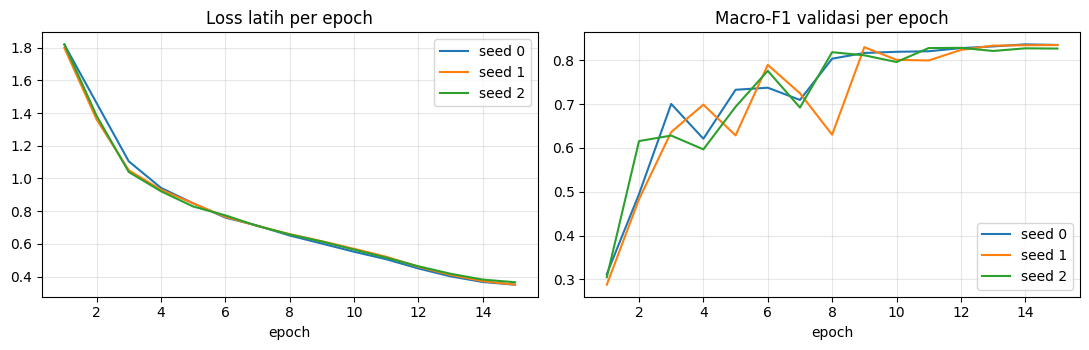

,loss_akhir,F1_akhir,F1_terbaik,epoch_terbaik
seed,,,,
0,0.3499,0.8347,0.8361,14
1,0.3502,0.8345,0.8345,15
2,0.3650,0.8264,0.8282,12


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for sd in SEEDS:
    h = np.array(FINAL[sd]['hist'])
    ax[0].plot(range(1, len(h) + 1), h[:, 0], label=f'seed {sd}')
    ax[1].plot(range(1, len(h) + 1), h[:, 1], label=f'seed {sd}')
ax[0].set_title('Loss latih per epoch'); ax[1].set_title('Macro-F1 validasi per epoch')
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

rows = []
for sd in SEEDS:
    h = np.array(FINAL[sd]['hist'])
    rows.append(dict(seed=sd, loss_akhir=h[-1, 0], F1_akhir=h[-1, 1], F1_terbaik=h[:, 1].max(), epoch_terbaik=int(h[:, 1].argmax()) + 1))
display(pd.DataFrame(rows).set_index('seed').round(4))

## 3. Ketika data sensor tidak terekam

Sekitar 5% unit tidak memiliki data sensor sama sekali, dan proporsi NaN pada data uji serupa dengan data latih. Model final yang sama diuji kembali dengan sensor dikosongkan (sinyal 0 dan mask 0) pada seluruh data validasi, sehingga diperoleh ukuran ketahanan terhadap hilangnya modalitas sensor. Sebagai pembanding, model gambar saja dari notebook fusi memperoleh macro-F1 0,613.

In [8]:
for sd in SEEDS:
    ringkas(f'Final sensor hilang seed {sd}', yv, FINAL[sd]['val_off'].argmax(1), lini_va)
P_ens_off = np.mean([FINAL[sd]['val_off'] for sd in SEEDS], axis=0)
ringkas('Final sensor hilang ansambel', yv, P_ens_off.argmax(1), lini_va)

tab = pd.DataFrame({
    'sensor ada': [HASIL[f'Final seed {sd}']['total'] for sd in SEEDS] + [HASIL['Final ansambel 3 seed']['total']],
    'sensor hilang': [HASIL[f'Final sensor hilang seed {sd}']['total'] for sd in SEEDS] + [HASIL['Final sensor hilang ansambel']['total']]},
    index=[f'seed {sd}' for sd in SEEDS] + ['ansambel'])
tab['penurunan'] = tab['sensor ada'] - tab['sensor hilang']
display(tab.round(4))
print("pembanding: gambar saja (notebook fusi, seed 0):", IMG_ONLY_F1)

Final sensor hilang seed 0: macro-F1 0.5894 | lini A 0.6346 | lini B 0.4508
Final sensor hilang seed 1: macro-F1 0.5945 | lini A 0.6371 | lini B 0.4634
Final sensor hilang seed 2: macro-F1 0.5857 | lini A 0.6284 | lini B 0.4541
Final sensor hilang ansambel: macro-F1 0.6143 | lini A 0.6590 | lini B 0.4743


,sensor ada,sensor hilang,penurunan
seed 0,0.8347,0.5894,0.2453
seed 1,0.8345,0.5945,0.2400
seed 2,0.8264,0.5857,0.2408
ansambel,0.8471,0.6143,0.2328


pembanding: gambar saja (notebook fusi, seed 0): 0.6131


## 4. Prediksi data uji

Prediksi akhir adalah kelas dengan probabilitas rata-rata tertinggi dari ketiga model (ansambel). Berkas `prediksi_klasifikasi.csv` berisi kolom `id_unit` dan `kelas`, satu baris per unit uji. Berkas diperiksa terhadap jumlah baris, keunikan `id_unit`, dan nilai kelas yang sah, dan sebaran kelas prediksi dibandingkan dengan sebaran kelas pada data latih.

In [9]:
P_ens_te = np.mean([FINAL[sd]['test'] for sd in SEEDS], axis=0)
pred_te = P_ens_te.argmax(1)
assert 'id_unit' in meta_te.columns, f"kolom id_unit tidak ada, kolom tersedia: {list(meta_te.columns)}"

sub = pd.DataFrame({'id_unit': meta_te['id_unit'].values, 'kelas': [KELAS[i] for i in pred_te]})
assert len(sub) == len(meta_te) and sub['id_unit'].is_unique and set(sub['kelas']) <= set(KELAS)
sub.to_csv(f'{REPO}/prediksi_klasifikasi.csv', index=False)
print("tersimpan:", f'{REPO}/prediksi_klasifikasi.csv', "|", len(sub), "baris")
display(sub.head())

dist = pd.DataFrame({'latih (%)': 100 * pd.Series(y).map(dict(enumerate(KELAS))).value_counts(normalize=True),
                     'prediksi uji (%)': 100 * sub['kelas'].value_counts(normalize=True)}).loc[KELAS].round(2)
display(dist)
INFO['uji'] = {'n': int(len(sub)), 'sebaran_prediksi_persen': {k: float(v) for k, v in dist['prediksi uji (%)'].items()}}
simpan()

tersimpan: /content/UTSDEEPLEARNING/prediksi_klasifikasi.csv | 16000 baris


,id_unit,kelas
0,U412019,gores
1,U929275,retak
2,U845264,normal
3,U382231,normal
4,U156089,gores


,latih (%),prediksi uji (%)
normal,49.77,55.39
gores,11.71,9.74
noda,9.94,8.56
retak,7.51,6.50
gelembung,7.15,7.14
las_dingin,9.01,8.30
kontaminasi,4.91,4.38


Titik simpan pertama: model final, hasil tiga seed, bobot, dan prediksi uji sudah selesai. Sel berikut meng-commit semuanya ke branch `task1-final`. Eksperimen tambahan pada bagian 5–7 dijalankan setelahnya.

In [10]:
%cd /content/UTSDEEPLEARNING
!git add kode/task1_klasifikasi/coteaching.py kode/task1_klasifikasi/hasil/final_tiga_seed.json kode/task1_klasifikasi/bobot/*.pt prediksi_klasifikasi.csv
!git commit -m "Task 1: model final 3 seed, bobot, dan prediksi uji"
!git push origin task1-final

/content/UTSDEEPLEARNING
[task1-final e044cac] Task 1: model final 3 seed, bobot, dan prediksi uji
 6 files changed, 16180 insertions(+)
 create mode 100644 kode/task1_klasifikasi/bobot/fusi_a1_aug_seed0.pt
 create mode 100644 kode/task1_klasifikasi/bobot/fusi_a1_aug_seed1.pt
 create mode 100644 kode/task1_klasifikasi/bobot/fusi_a1_aug_seed2.pt
 create mode 100644 kode/task1_klasifikasi/coteaching.py
 create mode 100644 kode/task1_klasifikasi/hasil/final_tiga_seed.json
 create mode 100644 prediksi_klasifikasi.csv
Enumerating objects: 16, done.
Counting objects: 100% (16/16), done.
Delta compression using up to 2 threads
Compressing objects: 100% (12/12), done.
Writing objects: 100% (12/12), 8.13 MiB | 6.84 MiB/s, done.
Total 12 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
remote: 
remote: Create a pull request for 'task1-final' on GitHub by visiting:
remote:      https://github.com/rafiptrnto/UTSDEEPLEARNING/pull/new/

## 5. Diagnosis pergeseran domain: pelatihan hanya lini A

Pada notebook sebelumnya, model yang dilatih hanya dengan lini A hampir gagal total pada lini B (macro-F1 0,129, dibanding 0,723 bila lini B ikut dilatih), tetapi normalisasi per lini dan augmentasi tidak menyempitkan selisih A–B ketika kedua lini ada dalam pelatihan. Ada dua kemungkinan: teknik tersebut memang tidak efektif untuk pergeseran ini, atau efeknya tidak terlihat karena data lini B sudah tersedia dalam pelatihan. Untuk membedakannya, kedua teknik diuji pada skenario yang ekstrem: pelatihan hanya lini A dengan normalisasi dan augmentasi (D1), dibandingkan dengan tanpa keduanya (D). Bila D1 jauh lebih baik dari D pada lini B, teknik tersebut menangani pergeseran citra; bila tidak, pergeseran lini B bersumber pada hal lain.

In [11]:
tr_A = tr_idx[lc[tr_idx] == 0]
def jalankan_A(nama, aug, norm):
    nrm = (mu_l, sd_l) if norm else None
    model = FusionNet()
    fit3(model, X_img, X_sen, y, lc, tr_A, va_idx, epochs=EPOCHS, class_weight=cw, p_drop=0.3,
         aug=aug, norm=nrm, device=device, seed=SEEDS[0], y_eval=y)
    P = predict3(model, vl_all, device, norm=nrm)
    PRED[nama] = P
    ringkas(nama, yv, P.argmax(1), lini_va)
    del model; torch.cuda.empty_cache()

N_D, N_D1 = 'D Latih lini A saja', 'D1 Latih lini A + normalisasi + augmentasi'
jalankan_A(N_D, aug=False, norm=False)
jalankan_A(N_D1, aug=True, norm=True)

mB = lini_va == 'B'
sebar = pd.DataFrame({n: pd.Series([KELAS[i] for i in PRED[n][mB].argmax(1)]).value_counts() for n in [N_D, N_D1]}).reindex(KELAS).fillna(0).astype(int)
sebar['label asli'] = pd.Series([KELAS[i] for i in yv[mB]]).value_counts().reindex(KELAS).values
print("Sebaran kelas prediksi pada lini B (validasi):")
display(sebar)

ep 1: loss 1.7480 | val macro-F1 0.3393
ep 2: loss 1.2124 | val macro-F1 0.5093
ep 3: loss 0.9033 | val macro-F1 0.5602
ep 4: loss 0.7525 | val macro-F1 0.6493
ep 5: loss 0.6359 | val macro-F1 0.5201
ep 6: loss 0.5675 | val macro-F1 0.5366
ep 7: loss 0.5099 | val macro-F1 0.5012
ep 8: loss 0.4683 | val macro-F1 0.5991
ep 9: loss 0.4252 | val macro-F1 0.6273
ep 10: loss 0.3660 | val macro-F1 0.6665
ep 11: loss 0.3247 | val macro-F1 0.6881
ep 12: loss 0.2768 | val macro-F1 0.6559
ep 13: loss 0.2400 | val macro-F1 0.6687
ep 14: loss 0.2136 | val macro-F1 0.6723
ep 15: loss 0.2026 | val macro-F1 0.6754
D Latih lini A saja: macro-F1 0.6754 | lini A 0.8707 | lini B 0.1187
ep 1: loss 1.8059 | val macro-F1 0.2410
ep 2: loss 1.3667 | val macro-F1 0.5616
ep 3: loss 0.9451 | val macro-F1 0.3803
ep 4: loss 0.8041 | val macro-F1 0.6121
ep 5: loss 0.7100 | val macro-F1 0.4733
ep 6: loss 0.6256 | val macro-F1 0.6465
ep 7: loss 0.5422 | val macro-F1 0.4533
ep 8: loss 0.4918 | val macro-F1 0.6567
ep 9:

,D Latih lini A saja,D1 Latih lini A + normalisasi + augmentasi,label asli
normal,1,3,1205
gores,129,74,278
noda,17,38,241
retak,1772,2169,181
gelembung,48,49,171
las_dingin,1,1,215
kontaminasi,439,73,116


## 6. Perbandingan dengan model dasar pada tiga seed

Pada seed 0, selisih model dengan augmentasi terhadap model dasar tanpa augmentasi hanya 0,003. Untuk menilai apakah augmentasi benar-benar membantu, model dasar (tanpa augmentasi) dilatih dengan seed yang sama dan dibandingkan dengan rerata dan simpangan baku antar seed. Selisih yang lebih kecil daripada simpangan baku antar seed tidak dianggap bermakna.

In [12]:
R0 = {}
if BANDINGKAN_R0:
    for sd in SEEDS:
        print(f"--- model dasar (tanpa augmentasi), seed {sd} ---")
        R0[sd] = latih_final(sd, aug=False, simpan_bobot=False)
        ringkas(f'Dasar tanpa augmentasi seed {sd}', yv, R0[sd]['val'].argmax(1), lini_va)
    tab = pd.DataFrame({
        'model dasar (tanpa augmentasi)': [HASIL[f'Dasar tanpa augmentasi seed {sd}']['total'] for sd in SEEDS],
        'model final (dengan augmentasi)': [HASIL[f'Final seed {sd}']['total'] for sd in SEEDS]}, index=[f'seed {sd}' for sd in SEEDS])
    tab.loc['rerata'] = tab.loc[[f'seed {sd}' for sd in SEEDS]].mean()
    tab.loc['simpangan baku'] = tab.loc[[f'seed {sd}' for sd in SEEDS]].std(ddof=1)
    display(tab.round(4))
else:
    print("BANDINGKAN_R0 = False, bagian ini dilewati.")

--- model dasar (tanpa augmentasi), seed 0 ---
ep 1: loss 1.7675 | val macro-F1 0.2731
ep 2: loss 1.2572 | val macro-F1 0.6927
ep 3: loss 1.0110 | val macro-F1 0.7329
ep 4: loss 0.8908 | val macro-F1 0.7203
ep 5: loss 0.8064 | val macro-F1 0.7748
ep 6: loss 0.7311 | val macro-F1 0.7812
ep 7: loss 0.6720 | val macro-F1 0.6977
ep 8: loss 0.6275 | val macro-F1 0.8096
ep 9: loss 0.5883 | val macro-F1 0.7932
ep 10: loss 0.5350 | val macro-F1 0.7958
ep 11: loss 0.4824 | val macro-F1 0.8341
ep 12: loss 0.4303 | val macro-F1 0.8397
ep 13: loss 0.3779 | val macro-F1 0.8349
ep 14: loss 0.3376 | val macro-F1 0.8376
ep 15: loss 0.3164 | val macro-F1 0.8354
Dasar tanpa augmentasi seed 0: macro-F1 0.8354 | lini A 0.8704 | lini B 0.7295
--- model dasar (tanpa augmentasi), seed 1 ---
ep 1: loss 1.7607 | val macro-F1 0.4001
ep 2: loss 1.2664 | val macro-F1 0.5569
ep 3: loss 0.9972 | val macro-F1 0.6428
ep 4: loss 0.8698 | val macro-F1 0.5265
ep 5: loss 0.7799 | val macro-F1 0.6891
ep 6: loss 0.7178 | v

,model dasar (tanpa augmentasi),model final (dengan augmentasi)
seed 0,0.8354,0.8347
seed 1,0.8361,0.8345
seed 2,0.8349,0.8264
rerata,0.8355,0.8319
simpangan baku,0.0006,0.0047


## 7. Co-teaching pada noise buatan

Label smoothing pada notebook sebelumnya tidak memberi perbaikan berarti pada label yang diacak 10% (macro-F1 0,782 menjadi 0,786). Sebagai teknik kedua, *co-teaching* diuji pada skenario yang sama persis: 10% label latih diacak dengan seed dan prosedur yang identik, sehingga label yang diubah sama dengan percobaan N0 dan N1. Forget rate diset 0,10, sama dengan proporsi noise yang disuntikkan. Pada data nyata proporsi noise tidak diketahui, sehingga pengaturan ini lebih menguntungkan co-teaching daripada kondisi sebenarnya dan hasilnya dibaca sebagai batas atas manfaat teknik ini. Hasil dibandingkan dengan N0 (tanpa smoothing) dan N1 (smoothing 0,1) dari notebook sebelumnya.

In [13]:
PREV = None
try:
    PREV = json.load(open(f'{OUT}/domain_noise_seed0.json'))['hasil']
    print("hasil notebook sebelumnya ditemukan:", [k for k in PREV if k.startswith('N')])
except FileNotFoundError:
    print("domain_noise_seed0.json belum ada di repositori (PR domain shift belum di-merge); pembanding N0/N1 dilewati.")

N_C = 'C Co-teaching | noise 10%'
if RUN_COTEACHING:
    rng = np.random.default_rng(SPLIT_SEED)
    y_noisy = y.copy()
    pilih = rng.choice(tr_idx, size=int(0.10 * len(tr_idx)), replace=False)
    y_noisy[pilih] = (y[pilih] + rng.integers(1, 7, size=len(pilih))) % 7
    print("label latih yang diubah:", len(pilih), "dari", len(tr_idx))
    n1, n2 = FusionNet(), FusionNet()
    fit_coteaching(n1, n2, X_img, X_sen, y_noisy, lc, tr_idx, va_idx, epochs=EPOCHS, class_weight=cw,
                   p_drop=0.3, aug=False, forget=0.10, device=device, seed=SPLIT_SEED, y_eval=y)
    P = predict3(n1, vl_all, device)
    PRED[N_C] = P
    ringkas(N_C, yv, P.argmax(1), lini_va)
    del n1, n2; torch.cuda.empty_cache()
    if PREV:
        tab = pd.DataFrame({k: {x: PREV[k][x] for x in ['total', 'A', 'B']} for k in PREV if k.startswith('N')}).T
        tab.loc[N_C] = [HASIL[N_C][x] for x in ['total', 'A', 'B']]
        tab.columns = ['macro-F1', 'lini A', 'lini B']
        display(tab.round(4))
else:
    print("RUN_COTEACHING = False, bagian ini dilewati.")

hasil notebook sebelumnya ditemukan: ['N0 Noise 10% | tanpa smoothing', 'N1 Noise 10% | smoothing 0,1']
label latih yang diubah: 3840 dari 38400
ep 1: forget 0.000 | loss 1.7584 | val macro-F1 (jaringan 1) 0.1942
ep 2: forget 0.020 | loss 1.3702 | val macro-F1 (jaringan 1) 0.3914
ep 3: forget 0.040 | loss 1.1017 | val macro-F1 (jaringan 1) 0.6317
ep 4: forget 0.060 | loss 0.9299 | val macro-F1 (jaringan 1) 0.6178
ep 5: forget 0.080 | loss 0.7810 | val macro-F1 (jaringan 1) 0.7155
ep 6: forget 0.100 | loss 0.6422 | val macro-F1 (jaringan 1) 0.5551
ep 7: forget 0.100 | loss 0.5932 | val macro-F1 (jaringan 1) 0.7671
ep 8: forget 0.100 | loss 0.5470 | val macro-F1 (jaringan 1) 0.8109
ep 9: forget 0.100 | loss 0.5200 | val macro-F1 (jaringan 1) 0.7987
ep 10: forget 0.100 | loss 0.4744 | val macro-F1 (jaringan 1) 0.7677
ep 11: forget 0.100 | loss 0.4382 | val macro-F1 (jaringan 1) 0.8221
ep 12: forget 0.100 | loss 0.4007 | val macro-F1 (jaringan 1) 0.8301
ep 13: forget 0.100 | loss 0.3568 | 

,macro-F1,lini A,lini B
N0 Noise 10% | tanpa smoothing,0.7815,0.8228,0.6593
"N1 Noise 10% | smoothing 0,1",0.7861,0.8256,0.6673
C Co-teaching | noise 10%,0.8311,0.8690,0.7140


## 8. Ringkasan dan kesimpulan

Kesimpulan di bawah disusun otomatis dari hasil di atas, sehingga seluruh angka konsisten dengan tabel.

In [14]:
def _f(x): return f"{x:.3f}".replace('.', ',')
def _d(x): return ('+' if x >= 0 else '−') + f"{abs(x):.3f}".replace('.', ',')

def buat_kesimpulan3(H, final, prev):
    t = []
    tot = np.array([H[f'Final seed {sd}']['total'] for sd in SEEDS])
    A = np.array([H[f'Final seed {sd}']['A'] for sd in SEEDS]); B = np.array([H[f'Final seed {sd}']['B'] for sd in SEEDS])
    ens = H['Final ansambel 3 seed']
    t.append(f"**1. Model final.** Macro-F1 validasi tiga seed adalah {_f(tot.mean())} ± {_f(tot.std(ddof=1))} (rerata ± simpangan baku; "
             f"rentang {_f(tot.min())}–{_f(tot.max())}), dengan lini A {_f(A.mean())} ± {_f(A.std(ddof=1))} dan lini B {_f(B.mean())} ± {_f(B.std(ddof=1))}. "
             f"Ansambel tiga model mencapai {_f(ens['total'])} ({_d(ens['total'] - tot.mean())} terhadap rerata model tunggal); lini A {_f(ens['A'])}, lini B {_f(ens['B'])}. "
             f"Selisih lini A dan B pada ansambel adalah {_f(ens['A'] - ens['B'])}.")

    hs = [np.array(final[sd]['hist']) for sd in SEEDS]
    akhir = np.mean([h[-1, 1] for h in hs]); terbaik = np.mean([h[:, 1].max() for h in hs])
    loss0 = np.mean([h[0, 0] for h in hs]); loss1 = np.mean([h[-1, 0] for h in hs])
    stabil = "mendatar di dekat nilai terbaiknya" if terbaik - akhir < 0.01 else "berada di bawah nilai terbaiknya selama pelatihan"
    t.append(f"**2. Kurva belajar.** Rerata loss latih turun dari {_f(loss0)} pada epoch pertama menjadi {_f(loss1)} pada epoch terakhir, "
             f"sedangkan macro-F1 validasi pada epoch terakhir rata-rata {_f(akhir)} dan {stabil} (rerata nilai terbaik {_f(terbaik)}). "
             f"Perbandingan antara loss latih dan macro-F1 validasi ini menjadi dasar pembahasan overfitting pada laporan.")

    off = H['Final sensor hilang ansambel']; offs = np.array([H[f'Final sensor hilang seed {sd}']['total'] for sd in SEEDS])
    t.append(f"**3. Sensor tidak terekam.** Dengan sensor dikosongkan, macro-F1 validasi tiga seed adalah {_f(offs.mean())} ± {_f(offs.std(ddof=1))} "
             f"(ansambel {_f(off['total'])}), turun {_f(ens['total'] - off['total'])} dari kondisi sensor ada. "
             f"Dibanding model gambar saja ({_f(IMG_ONLY_F1)}), selisihnya {_d(off['total'] - IMG_ONLY_F1)}; lini B {_f(off['B'])} dan lini A {_f(off['A'])}.")

    if N_D in H and N_D1 in H:
        dB = H[N_D1]['B'] - H[N_D]['B']
        s = (f"**4. Pergeseran domain pada pelatihan hanya lini A.** Tanpa normalisasi dan augmentasi, model mencapai macro-F1 {_f(H[N_D]['B'])} pada lini B; "
             f"dengan keduanya {_f(H[N_D1]['B'])} ({_d(dB)}). Pada lini A hasilnya {_f(H[N_D]['A'])} dan {_f(H[N_D1]['A'])}. ")
        s += ("Normalisasi dan augmentasi karenanya menangani sebagian pergeseran citra, meskipun efeknya tidak tampak ketika lini B sudah ada dalam pelatihan."
              if dB >= 0.05 else
              "Normalisasi dan augmentasi tidak menyelamatkan model pada lini B, sehingga pergeseran lini B tidak bersumber terutama pada kecerahan dan kontras global citra.")
        t.append(s)

    if all(f'Dasar tanpa augmentasi seed {sd}' in H for sd in SEEDS):
        r0 = np.array([H[f'Dasar tanpa augmentasi seed {sd}']['total'] for sd in SEEDS])
        d = tot.mean() - r0.mean(); sdv = max(tot.std(ddof=1), r0.std(ddof=1))
        arah = "melebihi" if abs(d) > sdv else "tidak melebihi"
        t.append(f"**5. Augmentasi dibanding model dasar.** Model dasar tanpa augmentasi: {_f(r0.mean())} ± {_f(r0.std(ddof=1))}; model final dengan augmentasi: {_f(tot.mean())} ± {_f(tot.std(ddof=1))}. "
                 f"Selisih rerata {_d(d)} {arah} simpangan baku antar seed ({_f(sdv)}), sehingga "
                 + ("keunggulan augmentasi dapat dianggap bermakna." if abs(d) > sdv and d > 0 else "perbedaan keduanya belum dapat dianggap bermakna secara statistik pada tiga seed."))

    if N_C in H and prev and 'N0 Noise 10% | tanpa smoothing' in prev:
        n0, n1 = prev['N0 Noise 10% | tanpa smoothing']['total'], prev['N1 Noise 10% | smoothing 0,1']['total']
        c = H[N_C]['total']
        t.append(f"**6. Label noise.** Dengan 10% label latih diacak, macro-F1 validasi adalah {_f(n0)} tanpa perlakuan, {_f(n1)} dengan label smoothing 0,1, dan {_f(c)} dengan co-teaching "
                 f"({_d(c - n0)} terhadap tanpa perlakuan, {_d(c - n1)} terhadap label smoothing). "
                 + ("Co-teaching memberi perbaikan yang lebih besar daripada label smoothing pada skenario ini, dengan catatan forget rate disetel sama dengan proporsi noise yang diketahui."
                    if c - n1 >= 0.01 else
                    "Co-teaching tidak memberi perbaikan yang lebih besar daripada label smoothing pada skenario ini."))

    t.append("**7. Keterbatasan.** Seluruh angka validasi berasal dari satu pembagian data; simpangan baku hanya mencerminkan variasi antar seed inisialisasi, bukan variasi antar pembagian data. "
             "Ansambel dipilih tanpa disetel pada data validasi, tetapi pemilihan R2 sebagai model final dilakukan setelah melihat hasil validasi seed 0. "
             "Prediksi uji dibuat dari model yang dilatih pada 80% data latih; 20% sisanya dipakai untuk validasi dan tidak ikut melatih.")
    return "\n\n".join(t)

display(Markdown(buat_kesimpulan3(HASIL, FINAL, PREV)))

**1. Model final.** Macro-F1 validasi tiga seed adalah 0,832 ± 0,005 (rerata ± simpangan baku; rentang 0,826–0,835), dengan lini A 0,868 ± 0,006 dan lini B 0,723 ± 0,007. Ansambel tiga model mencapai 0,847 (+0,015 terhadap rerata model tunggal); lini A 0,882, lini B 0,739. Selisih lini A dan B pada ansambel adalah 0,143.

**2. Kurva belajar.** Rerata loss latih turun dari 1,813 pada epoch pertama menjadi 0,355 pada epoch terakhir, sedangkan macro-F1 validasi pada epoch terakhir rata-rata 0,832 dan mendatar di dekat nilai terbaiknya (rerata nilai terbaik 0,833). Perbandingan antara loss latih dan macro-F1 validasi ini menjadi dasar pembahasan overfitting pada laporan.

**3. Sensor tidak terekam.** Dengan sensor dikosongkan, macro-F1 validasi tiga seed adalah 0,590 ± 0,004 (ansambel 0,614), turun 0,233 dari kondisi sensor ada. Dibanding model gambar saja (0,613), selisihnya +0,001; lini B 0,474 dan lini A 0,659.

**4. Pergeseran domain pada pelatihan hanya lini A.** Tanpa normalisasi dan augmentasi, model mencapai macro-F1 0,119 pada lini B; dengan keduanya 0,173 (+0,054). Pada lini A hasilnya 0,871 dan 0,880. Normalisasi dan augmentasi karenanya menangani sebagian pergeseran citra, meskipun efeknya tidak tampak ketika lini B sudah ada dalam pelatihan.

**5. Augmentasi dibanding model dasar.** Model dasar tanpa augmentasi: 0,835 ± 0,001; model final dengan augmentasi: 0,832 ± 0,005. Selisih rerata −0,004 tidak melebihi simpangan baku antar seed (0,005), sehingga perbedaan keduanya belum dapat dianggap bermakna secara statistik pada tiga seed.

**6. Label noise.** Dengan 10% label latih diacak, macro-F1 validasi adalah 0,782 tanpa perlakuan, 0,786 dengan label smoothing 0,1, dan 0,831 dengan co-teaching (+0,050 terhadap tanpa perlakuan, +0,045 terhadap label smoothing). Co-teaching memberi perbaikan yang lebih besar daripada label smoothing pada skenario ini, dengan catatan forget rate disetel sama dengan proporsi noise yang diketahui.

**7. Keterbatasan.** Seluruh angka validasi berasal dari satu pembagian data; simpangan baku hanya mencerminkan variasi antar seed inisialisasi, bukan variasi antar pembagian data. Ansambel dipilih tanpa disetel pada data validasi, tetapi pemilihan R2 sebagai model final dilakukan setelah melihat hasil validasi seed 0. Prediksi uji dibuat dari model yang dilatih pada 80% data latih; 20% sisanya dipakai untuk validasi dan tidak ikut melatih.

## 9. Penyimpanan hasil

Hasil seluruh eksperimen pada notebook ini disimpan dalam `hasil/final_tiga_seed.json`. Sel berikut meng-commit pembaruan hasil (prediksi uji dan bobot sudah di-commit pada titik simpan pertama).

In [15]:
simpan()
%cd /content/UTSDEEPLEARNING
!git add kode/task1_klasifikasi/hasil/final_tiga_seed.json
!git commit -m "Task 1: diagnosis domain, perbandingan 3 seed, co-teaching"
!git push origin task1-final

/content/UTSDEEPLEARNING
[task1-final 3e95570] Task 1: diagnosis domain, perbandingan 3 seed, co-teaching
 1 file changed, 84 insertions(+)
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (6/6), 1.41 KiB | 1.41 MiB/s, done.
Total 6 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/rafiptrnto/UTSDEEPLEARNING.git
   e044cac..3e95570  task1-final -> task1-final
